# Ablaciones y paridad de exportación nativa: método en la práctica

**Nivel:** 2  
**Requisitos previos:** Ablaciones y paridad de exportación nativa nivel 1  
**Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Cómo se comportan las ejecuciones nuevas de M03 y M04 en la tarea de cancelación C07?


## Objetivos

Para el nivel 2 de ablación y paridad de exportación nativa en C07, Distingue dos preguntas diferentes: Para el nivel 2 de ablación y paridad de exportación nativa en C07, si un componente cambia los resultados de tarea y si un puntuador exportado reproduce numéricamente su referencia. Para el nivel 2 de ablación y paridad de exportación nativa en C07, La ablación y la paridad numérica tienen estimandos separados; Para el nivel 2 de ablación y paridad de exportación nativa en C07, ninguna demuestra por sí sola inteligencia general ni superioridad.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 2 de ablación y paridad de exportación nativa en C07, El notebook lee artefactos comprometidos del producto. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Propietario: Para el nivel 2 de ablación y paridad de exportación nativa en C07, Neuraxis. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Repositorio: Para el nivel 2 de ablación y paridad de exportación nativa en C07, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 2 de ablación y paridad de exportación nativa en C07, Apache-2.0. Para el nivel 2 de ablación y paridad de exportación nativa en C07, El JSON es un artefacto experimental propio y congelado; Para el nivel 2 de ablación y paridad de exportación nativa en C07, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 2 de ablación y paridad de exportación nativa en C07, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 2 de ablación y paridad de exportación nativa en C07, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 2 de ablación y paridad de exportación nativa en C07, El manifiesto de publicación verifica los hashes. Para el nivel 2 de ablación y paridad de exportación nativa en C07, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 2 de ablación y paridad de exportación nativa en C07, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/research.json`
- `docs/evaluation/corrected-results.json`
- `data/derived/episodes/M03-C07-nominal-40000.json`
- `data/derived/episodes/M04-C07-nominal-40000.json`
- `data/derived/episodes/M11-C07-nominal-40000.json`
- `data/derived/episodes/M12-C07-nominal-40000.json`


## Método

Para el nivel 2 de ablación y paridad de exportación nativa en C07, Una ablación pregunta si quitar un componente declarado cambia resultados bajo el protocolo probado. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Las cuatro ablaciones M12 de Neuraxis mantienen los mismos 1.160 éxitos de 1.200 que el método completo; Para el nivel 2 de ablación y paridad de exportación nativa en C07, por tanto, estos experimentos no miden contribución al éxito de memoria, efectos, aplazamiento o invalidación. Para el nivel 2 de ablación y paridad de exportación nativa en C07, La igualdad no prueba que esos componentes nunca importen: Para el nivel 2 de ablación y paridad de exportación nativa en C07, quizá los casos no crean las oportunidades necesarias. Para el nivel 2 de ablación y paridad de exportación nativa en C07, La paridad de exportación compara predicciones nativas con valores de referencia en un conjunto finito de vectores y tolerancia declarada. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Pasar reduce el riesgo de deriva de implementación para esas entradas, pero no informa calibración, éxito, robustez, autorización ni valores no probados. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, La ablación estima la contribución de un componente solo cuando el controlador completo y el reducido comparten casos, semillas y presupuesto, y la única diferencia controlada es el componente retirado. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, Si todas las ablaciones repiten el resultado completo, el experimento no observa contribución marginal en esta suite. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, no prueba que el componente sea inútil en cualquier contexto. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, La paridad numérica pregunta si la exportación nativa aproxima una referencia dentro de una tolerancia declarada. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, es un estimando distinto del éxito de tarea o la contribución causal. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, Registra dominio de entrada, precisión, tolerancia y error absoluto máximo. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, un error pequeño en estados muestreados no garantiza comportamiento seguro fuera del dominio. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, Una conclusión sólida separa ablación conductual, paridad numérica y resultado de extremo a extremo, y nombra la evidencia de cada una sin sustituirlas. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, En este nivel, conserva identificadores e insumos emparejados para controladores completos y reducidos, e informa deltas de resultado separados de errores numéricos. Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, para ablación y paridad de exportación nativa en C07, Una extensión útil agrega entradas cercanas a límites de decisión y fuera del rango de entrenamiento, y conserva la tolerancia antes de interpretar paridad como evidencia de despliegue.


### ablación y paridad de exportación nativa · nivel 2 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


In [2]:
# Carga las trazas propias y verifica sus hashes; nunca modifica los artefactos canónicos.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04", "M11", "M12"]
trace_methods = ["M03", "M04", "M11", "M12"]
sample_case = "C07"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Trazas verificadas por hash:", len(records))


Trazas verificadas por hash: 4


### ablación y paridad de exportación nativa · nivel 2 — Ejecuta las políticas publicadas y compara la corrida


### ablación y paridad de exportación nativa · nivel 2 — Compara la secuencia completa y no solo la primera acción


### ablación y paridad de exportación nativa · L2 — Construir la primera política ejecutable

En el nivel 2, construye M03 para ablación y paridad de exportación nativa con la fábrica pública y conserva su contrato de observación antes de muestrear C07.


In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M03"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M03


### ablación y paridad de exportación nativa · L2 — Ejecutar el método principal en el caso indicado

En el nivel 2 de ablación y paridad de exportación nativa, el evaluador ejecuta M03 en C07 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### ablación y paridad de exportación nativa · L2 — Construir una política de comparación independiente

Para el nivel 2 de ablación y paridad de exportación nativa, crea M04 como objeto nuevo para impedir que el estado recurrente de M03 contamine la comparación.


In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M04


### ablación y paridad de exportación nativa · L2 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 2 ejecuta M04 en el mismo C07, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### ablación y paridad de exportación nativa · L2 — Agregar los dos episodios ejecutados

En el nivel 2, el agregador resume dos episodios ejecutados de ablación y paridad de exportación nativa, and las afirmaciones entre familias aún requieren el benchmark completo.


In [7]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### ablación y paridad de exportación nativa · L2 — Resultados de políticas nuevas

Para el nivel 2 de ablación y paridad de exportación nativa en C07, El gráfico siguiente se calcula con los resultados de episodios de ablación y paridad de exportación nativa recién ejecutados en C07, no se copia de un artefacto congelado.


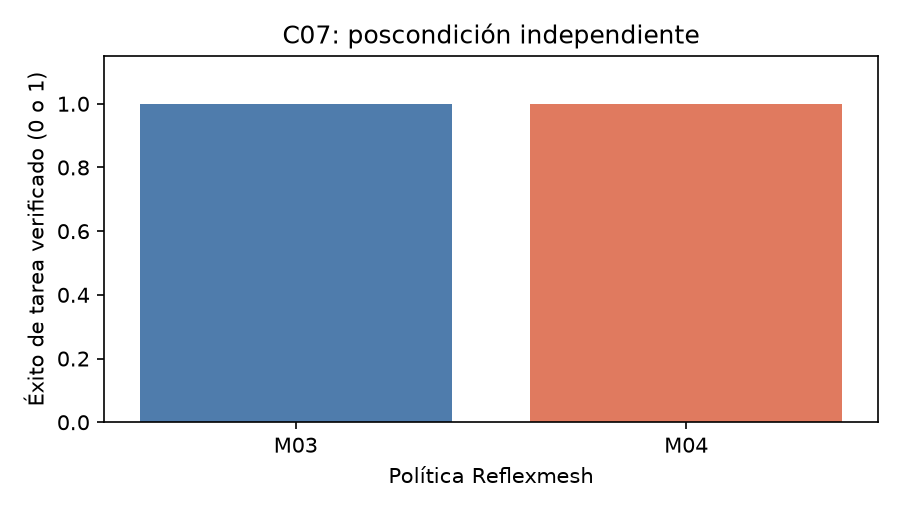

In [8]:
# Grafica los resultados verificados independientemente de las dos ejecuciones nuevas.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para ablación y paridad de exportación nativa, estas barras muestran resultados nuevos de poscondición de M03 y M04 en C07; Para el nivel 2 de ablación y paridad de exportación nativa en C07, éxito vale 1 y falla 0. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Lee el caso y la semilla antes de compararlas. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


### ablación y paridad de exportación nativa · L2 | Tiempo registrado del controlador

En el nivel 2, la figura de tiempos de ablación y paridad de exportación nativa usa registros congelados y verificados por hash para M03 y M04 en C07, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 2 para ablación y paridad de exportación nativa describe el entorno registrado bajo su caso, variante y semilla declarados.

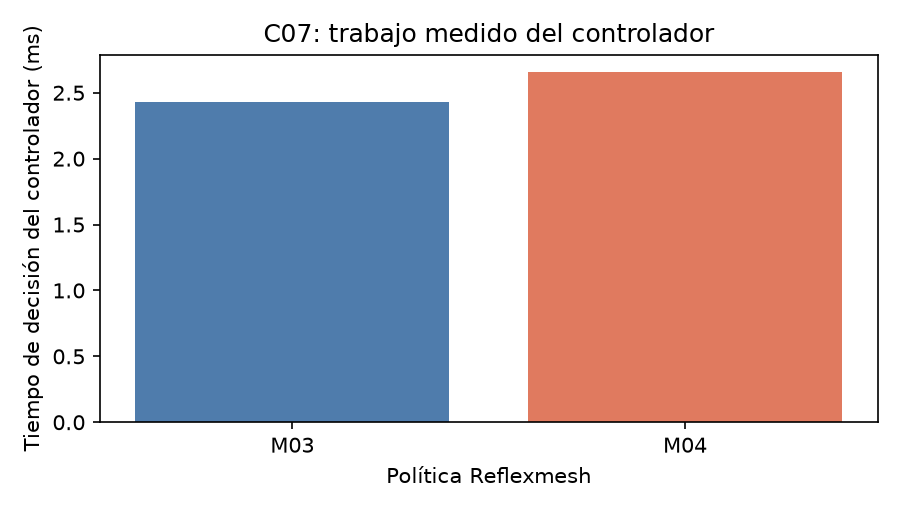

In [9]:
# Grafica el tiempo de control de los registros congelados y verificados por hash para los métodos emparejados.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: trabajo medido del controlador")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 2 para ablación y paridad de exportación nativa lee registros canónicos de M03/M04 en C07, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En esta lección de ablación y paridad de exportación nativa, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de ablación y paridad de exportación nativa ejecuta 2 episodios nuevos de M03 y M04 bajo condiciones C07 idénticas; conserva a la vista las familias y semillas de ablación y paridad de exportación nativa, porque la matriz contiene tareas diseñadas y no una muestra poblacional.

Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Las cuatro ablaciones conservan los mismos 1.160/1.200 éxitos de tarea, así que este experimento no muestra contribución al éxito por memoria, efectos, aplazamiento o invalidación. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Los presupuestos de ejecución difieren entre variantes, y las latencias medidas excluyen la construcción de características en Python. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, La paridad numérica no calibra la seguridad de la política.

Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Este paso de autoría no compromete salidas generadas; Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, Para el nivel 2 de ablación y paridad de exportación nativa en C07, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 2 de ablación y paridad de exportación nativa en C07, En el nivel 2, ablación y paridad de exportación nativa usa C07 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 2 de ablación y paridad de exportación nativa en C07, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [XGB](https://arxiv.org/abs/1603.02754)
- [PPO](https://arxiv.org/abs/1707.06347)
